In [1]:

import pandas as pd
df = pd.read_csv("../data/clean.csv")
print("Размер датасета:", df.shape)
print("Пропущенные значения:", df.isna().sum().sum())
print("Дубликаты:", df.duplicated().sum())
print("\nТипы данных:")
print(df.dtypes.value_counts())
print("\nПроверка оценок:")
for col in ["G1", "G2", "G3"]:
    print(
        f"{col}: min={df[col].min()}, "
        f"max={df[col].max()}"
    )
display(df.head())


Размер датасета: (649, 33)
Пропущенные значения: 0
Дубликаты: 0

Типы данных:
str      17
int64    16
Name: count, dtype: int64

Проверка оценок:
G1: min=0, max=19
G2: min=0, max=19
G3: min=0, max=19


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
raw = pd.read_csv("../data/student-por.csv", sep=";")
clean = pd.read_csv("../data/clean.csv")

comparison = pd.DataFrame({
    "Показатель": [
        "Количество строк",
        "Количество столбцов",
        "Пропущенные значения",
        "Полные дубликаты"
    ],
    "Исходные данные": [
        len(raw),
        raw.shape[1],
        raw.isna().sum().sum(),
        raw.duplicated().sum()
    ],
    "Очищенные данные": [
        len(clean),
        clean.shape[1],
        clean.isna().sum().sum(),
        clean.duplicated().sum()
    ]
})

display(comparison)


,Показатель,Исходные данные,Очищенные данные
0,Количество строк,649,649
1,Количество столбцов,33,33
2,Пропущенные значения,0,0
3,Полные дубликаты,0,0


In [3]:

import pandas as pd

df = pd.read_csv("../data/student-por.csv", sep=";")

cat_cols = df.select_dtypes(
    include=["object", "string"]
).columns

for col in cat_cols:
    print(f"\n{col}: {df[col].nunique()} категорий")
    print(sorted(df[col].dropna().unique().tolist()))



school: 2 категорий
['GP', 'MS']

sex: 2 категорий
['F', 'M']

address: 2 категорий
['R', 'U']

famsize: 2 категорий
['GT3', 'LE3']

Pstatus: 2 категорий
['A', 'T']

Mjob: 5 категорий
['at_home', 'health', 'other', 'services', 'teacher']

Fjob: 5 категорий
['at_home', 'health', 'other', 'services', 'teacher']

reason: 4 категорий
['course', 'home', 'other', 'reputation']

guardian: 3 категорий
['father', 'mother', 'other']

schoolsup: 2 категорий
['no', 'yes']

famsup: 2 категорий
['no', 'yes']

paid: 2 категорий
['no', 'yes']

activities: 2 категорий
['no', 'yes']

nursery: 2 категорий
['no', 'yes']

higher: 2 категорий
['no', 'yes']

internet: 2 категорий
['no', 'yes']

romantic: 2 категорий
['no', 'yes']


In [4]:

results = []

for col in cat_cols:
    s = df[col].astype("string")

    results.append({
        "Признак": col,
        "Категорий": df[col].nunique(),
        "Лишние пробелы": (s != s.str.strip()).sum(),
        "Пустые строки": s.str.strip().eq("").sum()
    })

category_check = pd.DataFrame(results)

display(category_check)

print("Всего лишних пробелов:",
      category_check["Лишние пробелы"].sum())

print("Всего пустых строк:",
      category_check["Пустые строки"].sum())


,Признак,Категорий,Лишние пробелы,Пустые строки
0,school,2,0,0
1,sex,2,0,0
2,address,2,0,0
3,famsize,2,0,0
4,Pstatus,2,0,0
5,Mjob,5,0,0
6,Fjob,5,0,0
7,reason,4,0,0
8,guardian,3,0,0
9,schoolsup,2,0,0


Всего лишних пробелов: 0
Всего пустых строк: 0


In [6]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error

df = pd.read_csv("../data/clean.csv")
X = df.drop(columns=["G3"])
y = df["G3"]
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)
num = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)
cat = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)
prep = make_column_transformer(
    (num, num_cols),
    (cat, cat_cols)
)
model = make_pipeline(prep, LinearRegression())

cv_r2 = cross_val_score(
    model, X_train, y_train, cv=5, scoring="r2"
)

cv_rmse = -cross_val_score(
    model, X_train, y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Train:", len(X_train))
print("Test:", len(X_test))
print("CV R²:", cv_r2.round(4))
print("Средний CV R²:", round(cv_r2.mean(), 4))
print("Средний CV RMSE:", round(cv_rmse.mean(), 4))
print("Test R²:", round(r2_score(y_test, pred), 4))
print("Test RMSE:", round(root_mean_squared_error(y_test, pred), 4))


Train: 486
Test: 163
CV R²: [0.7825 0.7728 0.8233 0.8665 0.8631]
Средний CV R²: 0.8216
Средний CV RMSE: 1.3625
Test R²: 0.8653
Test RMSE: 1.1655


In [8]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_csv("../data/clean.csv")

train, test = train_test_split(
    df, test_size=0.25, random_state=42
)

x = train["G2"].to_numpy(dtype=float)
y = train["G3"].to_numpy(dtype=float)

X = np.column_stack([np.ones(len(x)), x])

# 1. Обратная матрица
w_inv = np.linalg.inv(X.T @ X) @ X.T @ y

# 2. Решение системы уравнений
w_solve = np.linalg.solve(X.T @ X, X.T @ y)

# 3. Метод наименьших квадратов
w_lstsq = np.linalg.lstsq(X, y, rcond=None)[0]

# 4. Scikit-learn
lr = LinearRegression().fit(train[["G2"]], y)

print("inv:             ", w_inv.round(4))
print("solve:           ", w_solve.round(4))
print("lstsq:           ", w_lstsq.round(4))
print("LinearRegression:",
      np.r_[lr.intercept_, lr.coef_].round(4))


inv:              [-0.0559  1.0343]
solve:            [-0.0559  1.0343]
lstsq:            [-0.0559  1.0343]
LinearRegression: [-0.0559  1.0343]


In [9]:

X_dup = np.column_stack([
    np.ones(len(x)),
    x,
    x
])

print("Ранг матрицы:", np.linalg.matrix_rank(X_dup))
print("Количество столбцов:", X_dup.shape[1])

try:
    w_inv_dup = np.linalg.inv(X_dup.T @ X_dup) @ X_dup.T @ y
    print("inv:", w_inv_dup.round(4))
except np.linalg.LinAlgError as e:
    print("inv:", e)

try:
    w_solve_dup = np.linalg.solve(
        X_dup.T @ X_dup,
        X_dup.T @ y
    )
    print("solve:", w_solve_dup.round(4))
except np.linalg.LinAlgError as e:
    print("solve:", e)

w_lstsq_dup = np.linalg.lstsq(X_dup, y, rcond=None)[0]

print("lstsq:", w_lstsq_dup.round(4))

lr_dup = LinearRegression().fit(
    train[["G2"]].assign(G2_copy=train["G2"]), y
)

print("LinearRegression:",
      np.r_[lr_dup.intercept_, lr_dup.coef_].round(4))


Ранг матрицы: 2
Количество столбцов: 3
inv: Singular matrix
solve: Singular matrix
lstsq: [-0.0559  0.5172  0.5172]
LinearRegression: [-0.0559  0.5172  0.5172]


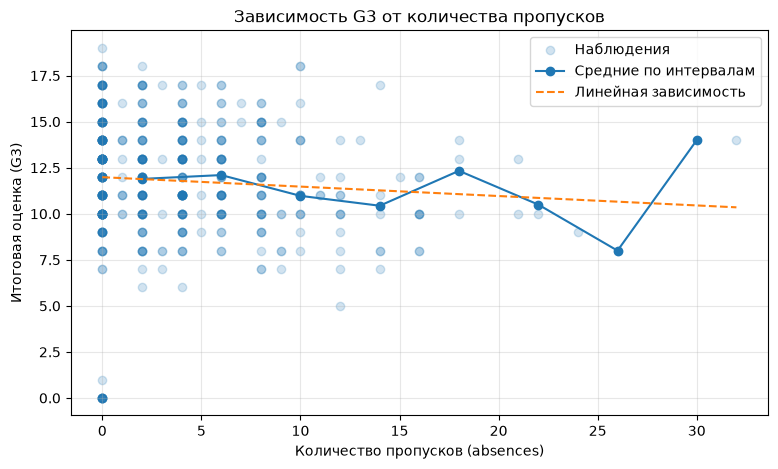

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/clean.csv")
train, test = train_test_split(
    df, test_size=0.25, random_state=42
)
groups = pd.cut(train["absences"], bins=8)
means = train.groupby(groups, observed=True)["G3"].mean()
midpoints = [interval.mid for interval in means.index]

plt.figure(figsize=(9, 5))
plt.scatter(
    train["absences"], train["G3"],
    alpha=0.2, label="Наблюдения"
)
plt.plot(
    midpoints, means.values,
    "o-", label="Средние по интервалам"
)
coef = np.polyfit(train["absences"], train["G3"], 1)
x_line = np.linspace(train["absences"].min(), train["absences"].max(), 100)
plt.plot(
    x_line, np.polyval(coef, x_line),
    "--", label="Линейная зависимость"
)
plt.xlabel("Количество пропусков (absences)")
plt.ylabel("Итоговая оценка (G3)")
plt.title("Зависимость G3 от количества пропусков")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [13]:

from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, KBinsDiscretizer
)
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings(
    "ignore",
    message="Bins whose width are too small.*",
    category=UserWarning
)

X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

num_wo = [c for c in num_cols if c != "absences"]

def make_prep_bins(n_bins, strategy):
    num = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    )

    cat = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    )

    bins = make_pipeline(
        SimpleImputer(strategy="median"),
        KBinsDiscretizer(
            n_bins=n_bins,
            encode="onehot",
            strategy=strategy
        )
    )

    return make_column_transformer(
        (num, num_wo),
        (bins, ["absences"]),
        (cat, cat_cols)
    )

results = []

for strategy in ["uniform", "quantile"]:
    for n_bins in [4, 8, 12, 20]:
        model = make_pipeline(
            make_prep_bins(n_bins, strategy),
            LinearRegression()
        )

        scores = cross_val_score(
            model, X_train, y_train,
            cv=5, scoring="r2"
        )

        results.append({
            "strategy": strategy,
            "n_bins": n_bins,
            "cv_r2": scores.mean()
        })

results_df = pd.DataFrame(results)

print(results_df.round(10).to_string(index=False))

print("\nЛучший вариант:")
print(results_df.loc[results_df["cv_r2"].idxmax()])


strategy  n_bins    cv_r2
 uniform       4 0.821217
 uniform       8 0.819486
 uniform      12 0.819100
 uniform      20 0.820591
quantile       4 0.824223
quantile       8 0.821945
quantile      12 0.824522
quantile      20 0.824525

Лучший вариант:
strategy    quantile
n_bins            20
cv_r2       0.824525
Name: 7, dtype: object
